# Does it matter where the letters fall on the model's grid?

Qwen3-VL cuts the image into 16-pixel patches and merges them 2 x 2 into 32-pixel tokens. In
`run_model.ipynb` the letters fell wherever their eccentricity put them, and the letter row
lay on a boundary between two rows of tokens.

Here the display is shifted (by at most half a token, so eccentricity and spacing stay the
same) so the letter row sits in the middle of a row of tokens, and the target is either

- **split**: cut in half by a token boundary, so each token holds one flanker and half the target, or
- **centred**: in the middle of one token.

**none** is the unshifted display from the first run, for comparison. Only the spacings where
a flanker and half the target fit in one token: gap 0 and 1 at the monitor resolution, gap 0 at
150 dpi, plus the letter alone. Random-letter flankers, since the model ignores "x".

Results go to `../data/model_results_alignment.csv`.

## Setup

In [1]:
import os
import sys

inColab = "google.colab" in sys.modules

if inColab:
  from google.colab import drive
  drive.mount("/content/drive")
  os.chdir("/content/drive/MyDrive/Projects/vlm-psychophysics/chapters/crowding/code")
  os.system("pip install -q -U transformers")

sys.path.insert(0, os.getcwd())
print("running in Colab:", inColab)
print("folder:", os.getcwd())

Mounted at /content/drive
running in Colab: True
folder: /content/drive/MyDrive/Projects/vlm-psychophysics/chapters/crowding/code


In [2]:
import time
import torch
import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt
from transformers       import AutoModelForImageTextToText, AutoProcessor
from transformers.utils import logging

import stimuli

logging.disable_progress_bar()
logging.set_verbosity_error()

if torch.cuda.is_available():
  device = "cuda"
  dtype  = torch.float16
else:
  device = "cpu"
  dtype  = torch.float32

print("device:", device)

device: cuda


In [3]:
modelName = "Qwen/Qwen3-VL-2B-Instruct"

model = AutoModelForImageTextToText.from_pretrained(modelName, dtype=dtype)
model = model.to(device)
model = model.eval()
proc  = AutoProcessor.from_pretrained(modelName)


def makeInputs(img, question):
  messages = [
    {"role": "user",
     "content": [
       {"type": "image", "image": img},
       {"type": "text",  "text":  question},
     ]}
  ]
  inputs = proc.apply_chat_template(messages,
                                    tokenize=True,
                                    add_generation_prompt=True,
                                    return_dict=True,
                                    return_tensors="pt")
  inputs = inputs.to(device)
  inputs["pixel_values"] = inputs["pixel_values"].to(dtype)
  return inputs


def nextWordScores(img, question):
  # one forward pass: a score for every word the model could say first
  inputs = makeInputs(img, question)
  with torch.no_grad():
    output = model(**inputs, logits_to_keep=1)
  return output.logits[0, -1].float().cpu()

print("model loaded")

model loaded


## The question and the scoring

One question for every display, with one letter or three, on either side of the cross:

> Look at the letters on one side of the cross. If there are three letters in a row, name the
> middle one. If there is only one letter, name it. Answer with a single lowercase letter.

The answer is the most likely of the 25 letters (a-z without x), so guessing gives 1/25 = 4%
correct, as for Bouma's observers. Bouma's observers could also say "illegible"; the model
can't.

In [4]:
question = ("Look at the letters on one side of the cross. If there are three letters in a row, "
            "name the middle one. If there is only one letter, name it. "
            "Answer with a single lowercase letter.")
letters  = stimuli.LETTERS

# token IDs of " a", " b", ... (with the leading space, as in notebook 01); each must be one token
letterIds = []
for L in letters:
  ids = proc.tokenizer.encode(" " + L, add_special_tokens=False)
  assert len(ids) == 1, L
  letterIds.append(ids[0])


def letterProbs(img):
  scores = nextWordScores(img, question)
  return torch.softmax(scores[letterIds], dim=0).numpy()

## A check: one display of each kind

The red lines are the 32-pixel tokens.

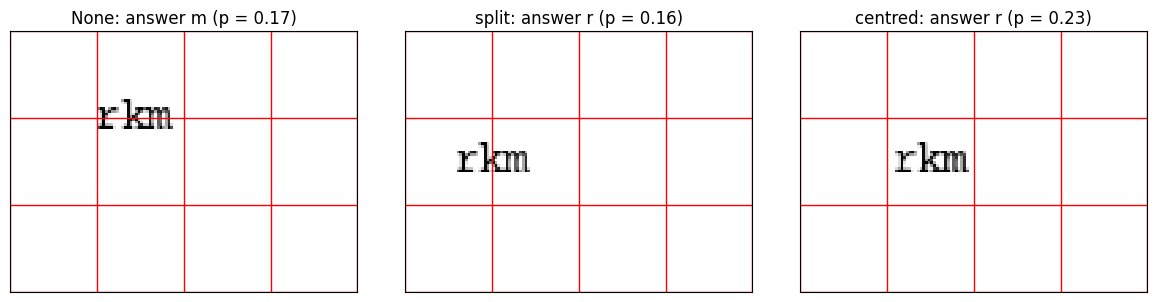

In [5]:
aligns = [None, "split", "centred"]
trial  = dict(target="k", ecc_deg=5, gap=0, side="right", inner_flanker="r", outer_flanker="m")

fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for j, align in enumerate(aligns):
  img   = stimuli.draw_trial(trial, "monitor", align=align)
  probs = letterProbs(img)
  x0    = int(img.width / 2 + 5 * stimuli.pixels_per_degree("monitor")) // 32 * 32 - 32
  y0    = img.height // 2 // 32 * 32 - 32
  axs[j].imshow(img.crop((x0, y0, x0 + 128, y0 + 96)), extent=(0, 128, 96, 0), interpolation="nearest")
  for g in range(0, 129, 32):
    axs[j].axvline(g, color="red", lw=1)
  for g in range(0, 97, 32):
    axs[j].axhline(g, color="red", lw=1)
  axs[j].set_title("%s: answer %s (p = %.2f)" % (align, letters[np.argmax(probs)], np.max(probs)))
  axs[j].set_xticks([])
  axs[j].set_yticks([])
plt.tight_layout()
plt.show()

## The run

About 6,000 trials, roughly 15 minutes on a T4. Saved every 500 trials; run the cell again to
continue after a disconnect.

In [6]:
gapsByResolution = {"monitor": [0, 1, None], "150dpi": [0, None]}
resultsFile      = "../data/model_results_alignment.csv"

if os.path.exists(resultsFile):
  results = pd.read_csv(resultsFile).to_dict("records")
else:
  results = []
done = set((r["resolution"], str(r["align"]), r["index"]) for r in results)


def save():
  pd.DataFrame(results).to_csv(resultsFile, index=False)


trials    = stimuli.make_trials("random")
startTime = time.time()
for resolution, gaps in gapsByResolution.items():
  for align in aligns:
    for trial in trials:
      if trial["gap"] not in gaps or (resolution, str(align), trial["index"]) in done:
        continue

      probs  = letterProbs(stimuli.draw_trial(trial, resolution, align=align))
      answer = letters[np.argmax(probs)]
      hasFlankers = trial["gap"] is not None

      results.append({**trial,
                      "model":             modelName,
                      "resolution":        resolution,
                      "align":             str(align),
                      "answer":            answer,
                      "correct":           answer == trial["target"],
                      "p_correct":         float(probs[letters.index(trial["target"])]),
                      "answer_is_flanker": hasFlankers and answer in (trial["inner_flanker"], trial["outer_flanker"])})
      if len(results) % 500 == 0:
        save()

    save()
    print("%-8s %-8s done after %.0f s" % (resolution, align, time.time() - startTime))

monitor  None     done after 136 s
monitor  split    done after 262 s
monitor  centred  done after 416 s
150dpi   None     done after 564 s
150dpi   split    done after 704 s
150dpi   centred  done after 845 s


## A first look

In [7]:
df = pd.DataFrame(results)
df["gap"] = df["gap"].fillna(-1).astype(int)        # -1 = no flankers
table = df.pivot_table(index=["resolution", "gap"], columns="align", values="correct")
print("proportion correct")
print(table.round(2))
print()
print("wrong answers that were a flanker")
print(df[~df["correct"] & (df["gap"] >= 0)].pivot_table(index=["resolution", "gap"], columns="align", values="answer_is_flanker").round(2))

proportion correct
align           None  centred  split
resolution gap                      
150dpi     -1   0.94     0.94   0.94
            0   0.88     0.82   0.85
monitor    -1   0.95     0.90   0.90
            0   0.71     0.66   0.62
            1   0.96     0.96   0.98

wrong answers that were a flanker
align           None  centred  split
resolution gap                      
150dpi     0    1.00     1.00   1.00
monitor    0    0.99     0.99   0.99
           1    1.00     1.00   1.00
